In [16]:
import pandas as pd

In [17]:
df = pd.read_csv('../results/2021/all_ts_2021.csv', delimiter=';')

14s

In [18]:
df.loc[df['author']=='�yz�y,��0],�II-�ೡ��N���[~��']

,author,commit_id,timestamp_utc0,timezone
5852186,"�yz�y,��0],�II-�ೡ��N���[~��",d89a9f0798f4b68a94a42dab491a1674e860b307,1418058247,0
5852187,"�yz�y,��0],�II-�ೡ��N���[~��",70a2e0a1951798dbe9855538706893ab38538d90,1383162195,0
5852188,"�yz�y,��0],�II-�ೡ��N���[~��",b66a332addbe73b8adf7695f8298a8ab95faf65a,1410548060,0
5852189,"�yz�y,��0],�II-�ೡ��N���[~��",ee2c5318f85fa0fc8f3241d011dc9064f8fa812c,1461509940,0
5852190,"�yz�y,��0],�II-�ೡ��N���[~��",3133a14c8991188a8db90421fa56e5c32fd89f27,1460560707,0
...,...,...,...,...
6207112,"�yz�y,��0],�II-�ೡ��N���[~��",bea10ad0d075564e46bd291d2d21e2d0d478b320,1425063820,0
6207113,"�yz�y,��0],�II-�ೡ��N���[~��",9eca778c5cc9888972ad396bf74f19f4d5857c94,1439412035,0
6207114,"�yz�y,��0],�II-�ೡ��N���[~��",0f30d703e8aba5b9a2959a8874cef621a80d7394,1429275063,0
6207115,"�yz�y,��0],�II-�ೡ��N���[~��",d10c118ebb60d540d8b23bfb5951716845995202,1424927080,0


In [3]:
df['author'].value_counts()

author
�\t���
;�e�A��TX��"�l�X�`�Qq�F��    539452
��;��g�M���3]1��4d�9�mA@�~���Ѻ      524431
�yz�y,��0],�II-�ೡ��N���[~��       354931
��7��LA�<���p�>���T�l������GA�+     262278
�X���r�0��*�.d��]ԝ�SQV�s���      262218
                                      ...  
�yH�\n���\rJ�eTU�ҭ�h��O��P�U,�-         2
�yG�����<���L�|D��jZ:J��kL҉           2
�yC�h��U�
��f'��+�D�
R�Y���>P��
          2

${V��a�ű�1o\t��8�<�����Z����h�          2

#���[��!TP\�!��Vh��\n8��.0�2         2
Name: count, Length: 76054, dtype: int64

In [4]:
author = '�yz�y,��0],�II-�ೡ��N���[~��'
set(df.loc[df['author']==author]['timezone'])

{-420, -240, 0}

In [21]:
df.loc[(df['author'] == author) & (df['timezone'] == -420)]

,author,commit_id,timestamp_utc0,timezone
5892292,"�yz�y,��0],�II-�ೡ��N���[~��",dacc36c40d94ea8162e001b92a81ad3966ad0911,1336117706,-420
5911643,"�yz�y,��0],�II-�ೡ��N���[~��",c53d8e343e50d4cf7ea9a6a81258848c2d893bfb,1336117706,-420


In [5]:
list_commit_tz1 = sorted([(pd.Timestamp(elt, unit='s').hour, pd.Timestamp(elt, unit='s').minute) for elt in list(df.loc[(df['author']==author) & (df['timezone'] == 0)]['timestamp_utc0'])], key=lambda x: (x[0], x[1]))
list_commit_tz2 = sorted([(pd.Timestamp(elt, unit='s').hour, pd.Timestamp(elt, unit='s').minute) for elt in list(df.loc[(df['author']==author) & (df['timezone'] == -240)]['timestamp_utc0'])], key=lambda x: (x[0], x[1])) 
list_commit_tz3 = sorted([(pd.Timestamp(elt, unit='s').hour, pd.Timestamp(elt, unit='s').minute) for elt in list(df.loc[(df['author']==author) & (df['timezone'] == -420)]['timestamp_utc0'])], key=lambda x: (x[0], x[1]))

In [6]:
import matplotlib.pyplot as plt
from collections import Counter

In [7]:
def round_to_half_hour(hour, minute):
    if minute >= 30:
        return (hour, 30)
    else:
        return (hour, 0)

In [8]:
rounded_time_tuples1 = [round_to_half_hour(hour, minute) for hour, minute in list_commit_tz1]
rounded_time_tuples2 = [round_to_half_hour(hour, minute) for hour, minute in list_commit_tz2]
rounded_time_tuples3 = [round_to_half_hour(hour, minute) for hour, minute in list_commit_tz3]

In [9]:

time_counts1 = Counter(rounded_time_tuples1)
time_counts2 = Counter(rounded_time_tuples2)
time_counts3 = Counter(rounded_time_tuples3)

In [10]:
# Generate all half-hour slots in the day
half_hour_slots = [f"{hour:02d}:{minute:02d}" for hour in range(24) for minute in (0, 30)]

counts1 = [time_counts1.get((int(slot.split(':')[0]), int(slot.split(':')[1])), 0) for slot in half_hour_slots]
counts2 = [time_counts2.get((int(slot.split(':')[0]), int(slot.split(':')[1])), 0) for slot in half_hour_slots]
counts3 = [time_counts3.get((int(slot.split(':')[0]), int(slot.split(':')[1])), 0) for slot in half_hour_slots]

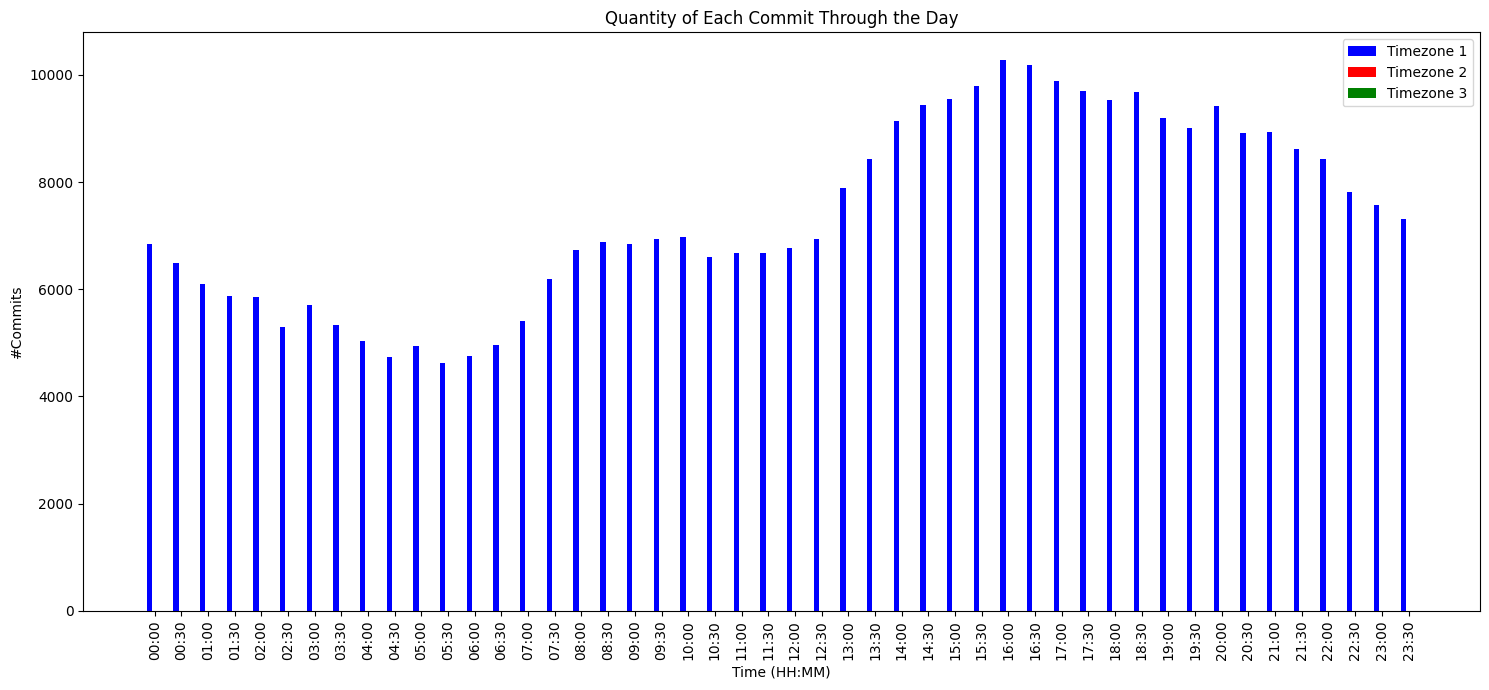

In [12]:
plt.figure(figsize=(15, 7))

plt.bar([x for x in range(len(half_hour_slots))], counts1, width=0.2, color='blue', align='center', label='Timezone 1')
plt.bar([x + 0.2 for x in range(len(half_hour_slots))], counts2, width=0.2, color='red', align='center', label='Timezone 2')
plt.bar([x + 0.4 for x in range(len(half_hour_slots))], counts3, width=0.2, color='green', align='center', label='Timezone 3')

plt.xlabel('Time (HH:MM)')
plt.ylabel('#Commits')
plt.title('Quantity of Each Commit Through the Day')
plt.xticks([x + 0.2 for x in range(len(half_hour_slots))], half_hour_slots, rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
print(rounded_time_tuples2)
print(rounded_time_tuples3)

[(4, 30)]
[(7, 30), (7, 30)]
